# 07 - Grad-CAM

Na imagem, o eixo vertical é a frequência (0 Hz em cima) e o horizontal é o tempo (90 s).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import tensorflow as tf

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

splits = pd.read_csv(PROJECT_ROOT / 'data' / 'annotations' / 'splits.csv')
classes = sorted(splits['classe'].unique())
teste = splits[splits['conjunto'] == 'teste']

X_test = np.array([np.array(Image.open(PROJECT_ROOT / c.replace('spectrograms', 'mod_spectograms')).convert('RGB').resize((224, 224))) / 255.0
                   for c in teste['caminho']], dtype='float32')
y_true = np.array([classes.index(c) for c in teste['classe']])

modelos = {
    'CNN': tf.keras.models.load_model(PROJECT_ROOT / 'models' / 'modelo_cnn.keras'),
    'FCNN': tf.keras.models.load_model(PROJECT_ROOT / 'models' / 'modelo_fcnn.keras'),
    'Encoder-Decoder': tf.keras.models.load_model(PROJECT_ROOT / 'models' / 'modelo_encdec.keras'),
}

## Grad-CAM

Última camada convolucional: `conv2d_2` (tem o mesmo nome nos três modelos).

In [2]:
last_conv_layer = modelos['CNN'].get_layer('conv2d_2')


def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    # Refaz o modelo devolvendo a saída da conv e a previsão
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = inputs
    for layer in model.layers:
        x = layer(x)
        if layer.name == last_conv_layer_name:
            conv_output = x
    grad_model = tf.keras.Model(inputs, [conv_output, x])

    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_array)
        score = preds[0, tf.argmax(preds[0])]
    grads = tape.gradient(score, conv_out)

    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.maximum(conv_out[0] @ pesos[:, None], 0)[..., 0]
    return (heatmap / (tf.reduce_max(heatmap) + 1e-10)).numpy()

## Galeria

Para cada modelo, as 2 imagens corretas e as 2 incorretas com maior confiança. Colunas: imagem original, mapa Grad-CAM e sobreposição.

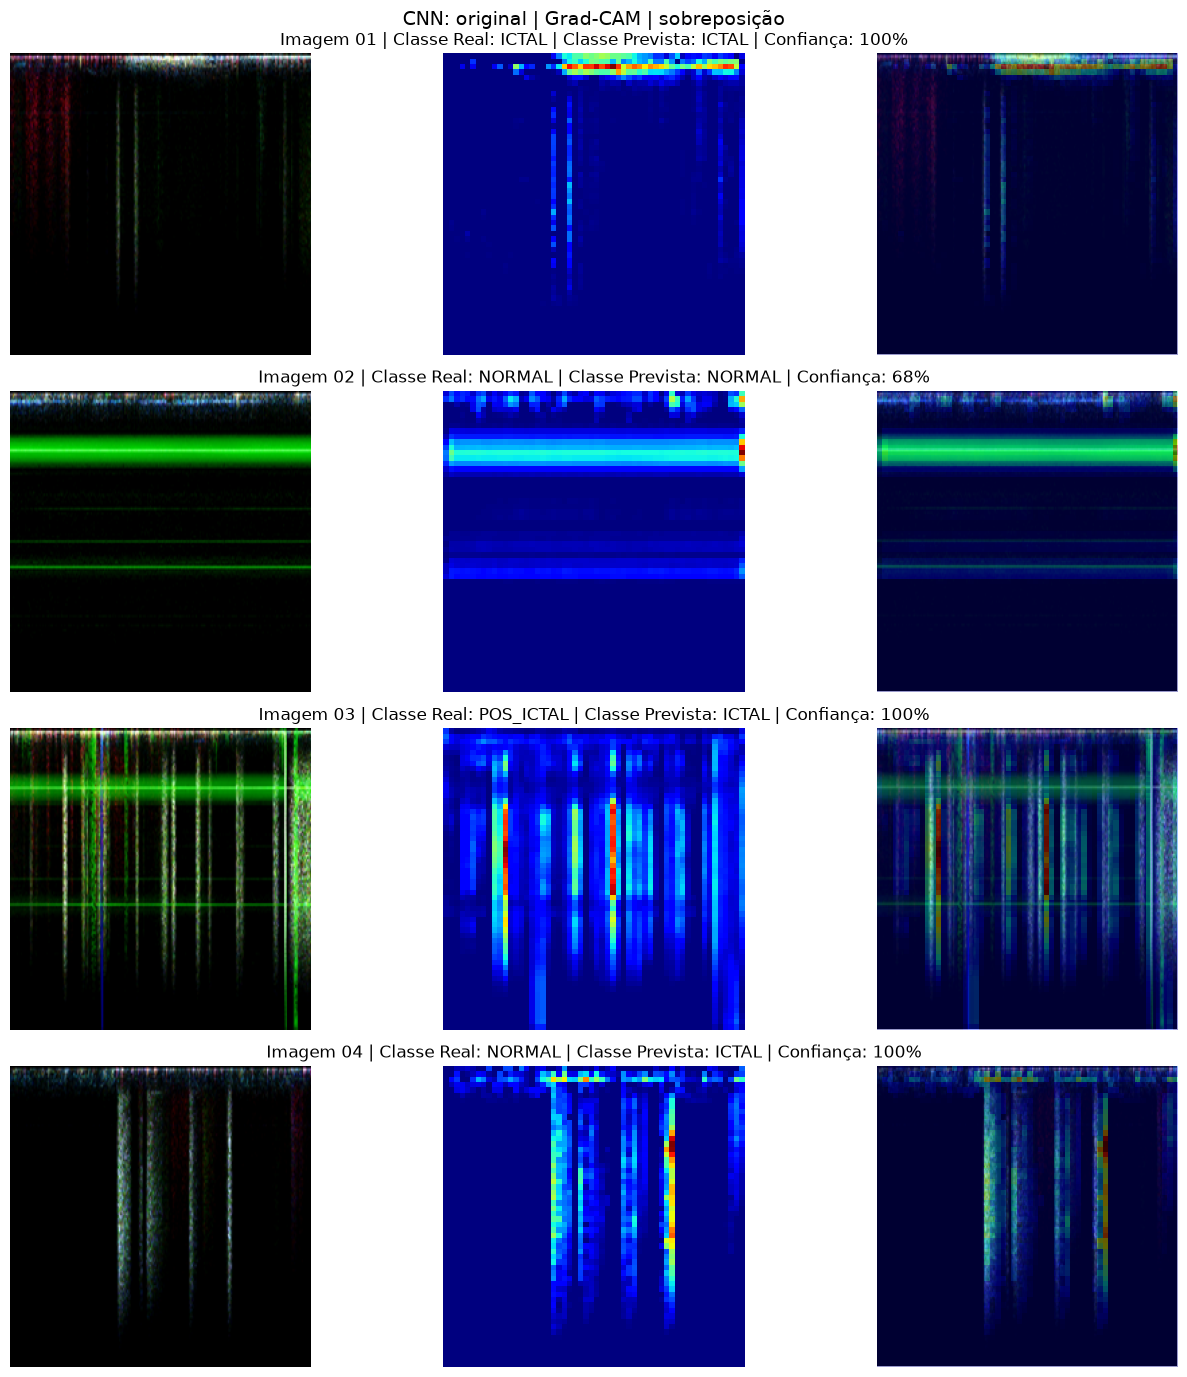

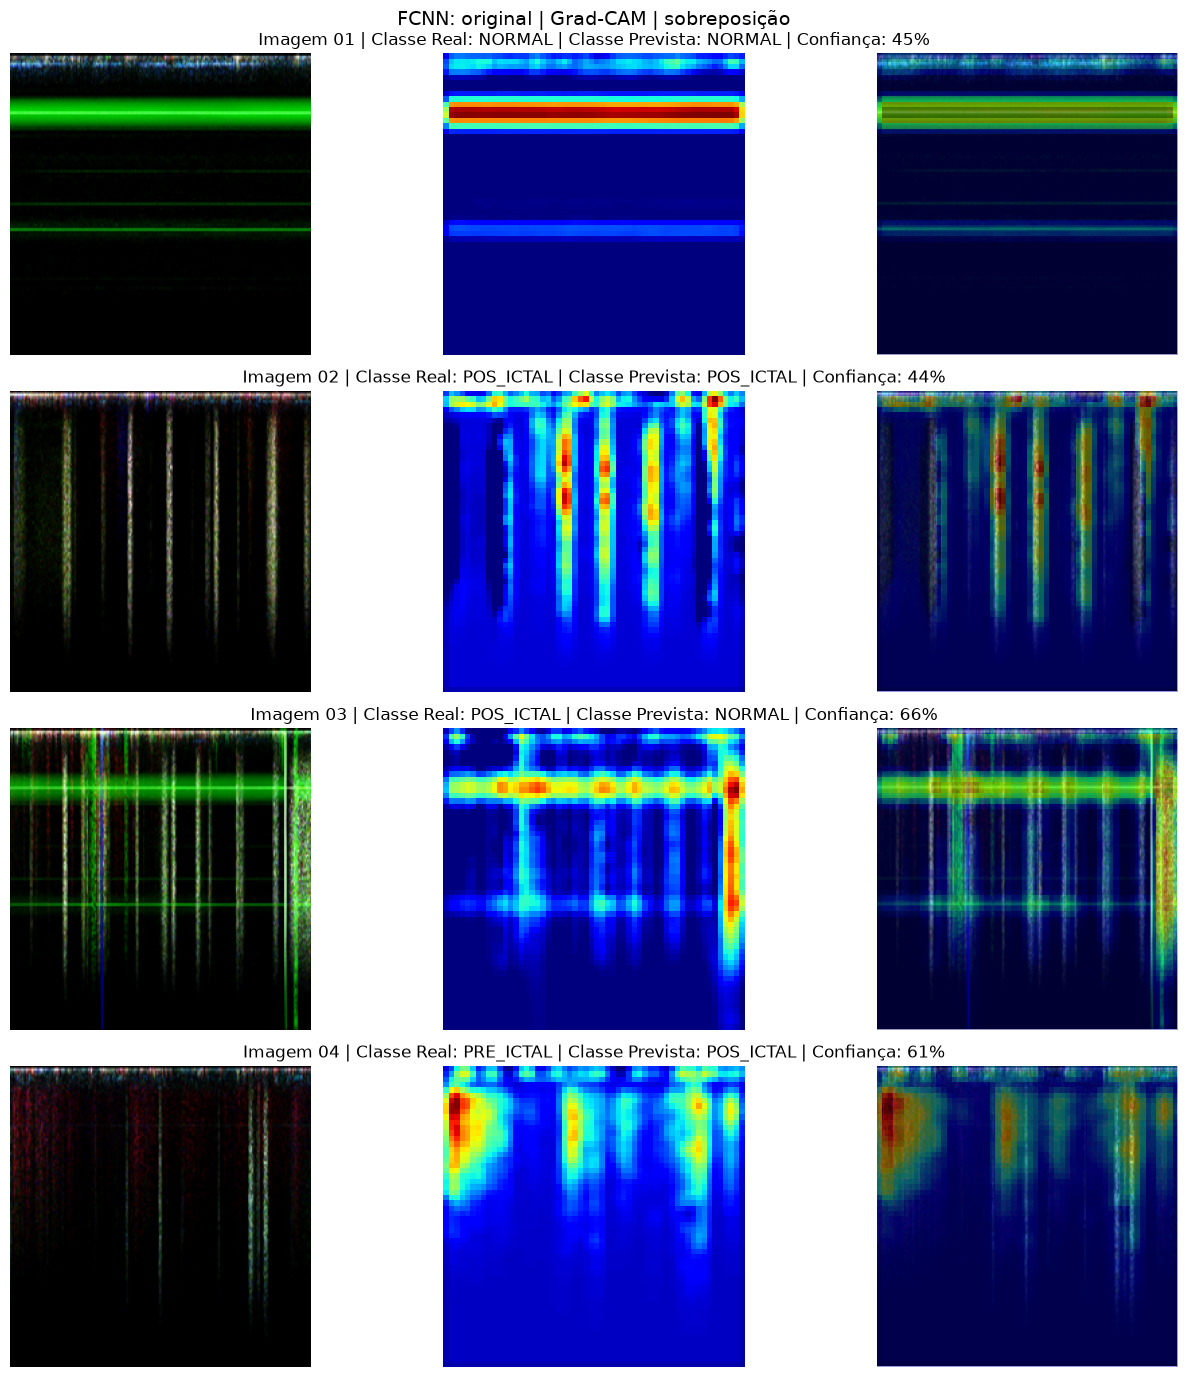

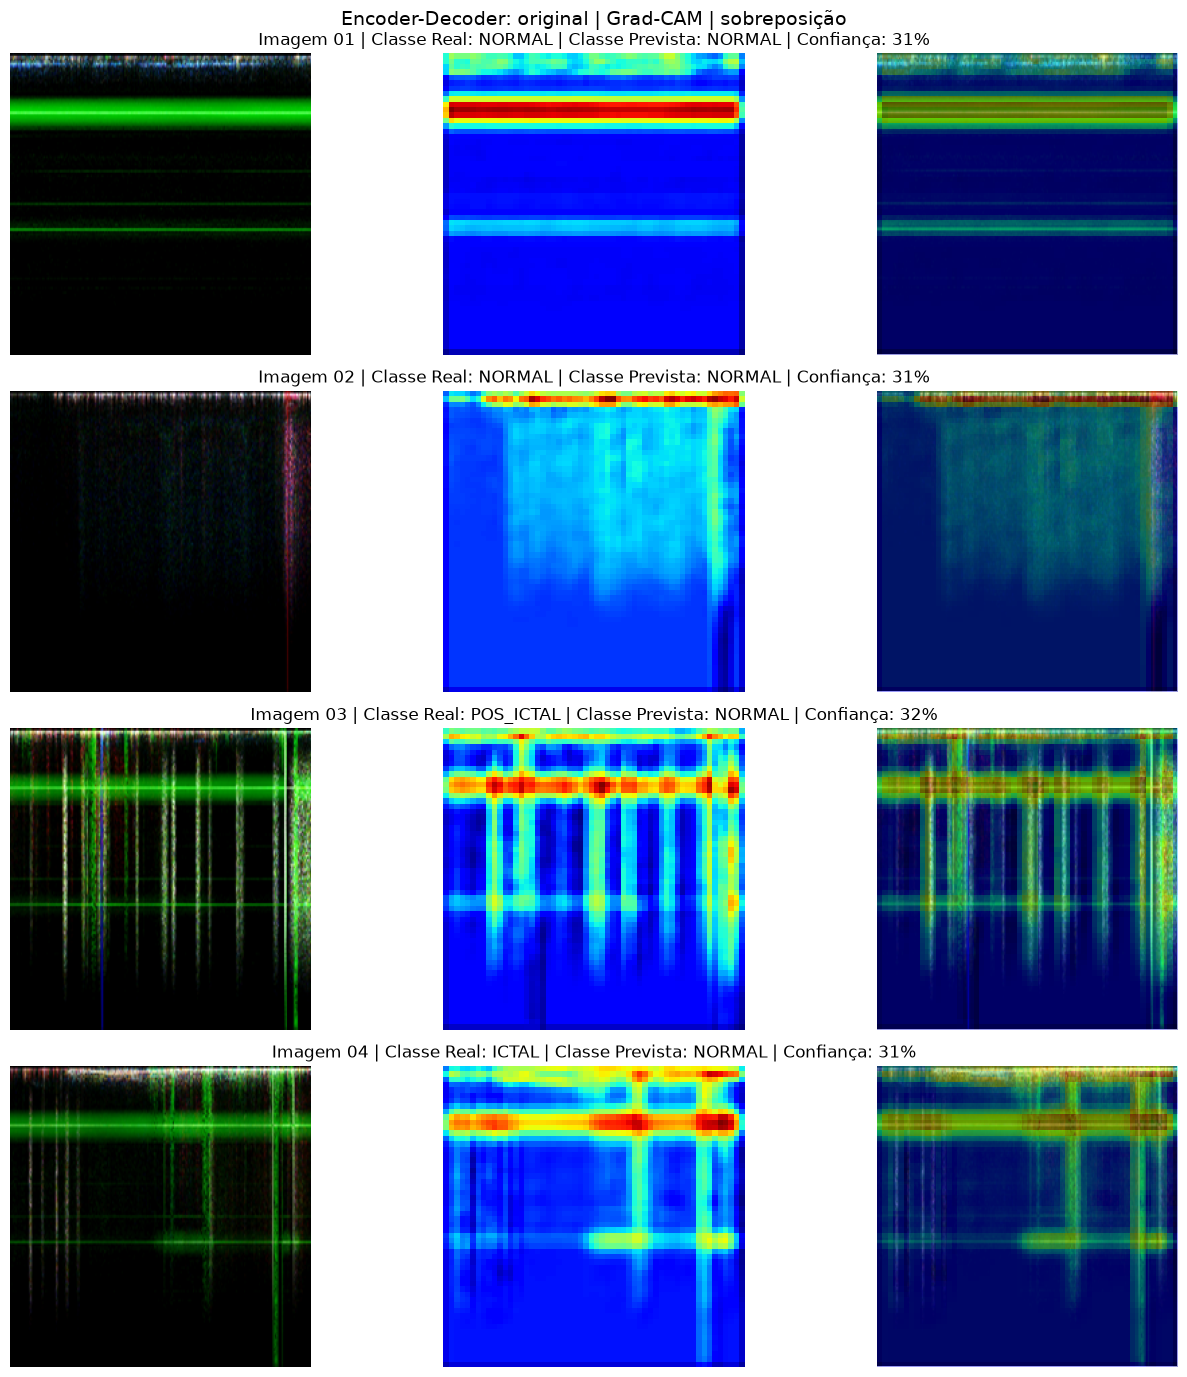

In [3]:
for nome, model in modelos.items():
    prob = model.predict(X_test, verbose=0)
    pred, conf = prob.argmax(axis=1), prob.max(axis=1)
    ordem = np.argsort(-conf, kind='stable')
    corretas = [i for i in ordem if pred[i] == y_true[i]][:2]
    incorretas = [i for i in ordem if pred[i] != y_true[i]][:2]

    fig, axes = plt.subplots(4, 3, figsize=(14, 14))
    fig.suptitle(f'{nome}: original | Grad-CAM | sobreposição', fontsize=14)
    for k, i in enumerate(corretas + incorretas):
        heatmap = make_gradcam_heatmap(X_test[i:i + 1], model, last_conv_layer.name)
        axes[k, 0].imshow(X_test[i])
        axes[k, 1].imshow(heatmap, cmap='jet')
        axes[k, 2].imshow(X_test[i])
        axes[k, 2].imshow(heatmap, cmap='jet', alpha=0.4, extent=(0, 224, 224, 0))
        axes[k, 1].set_title(f'Imagem {k + 1:02d} | Classe Real: {classes[y_true[i]]} | '
                             f'Classe Prevista: {classes[pred[i]]} | Confiança: {conf[i]:.0%}')
        for ax in axes[k]:
            ax.axis('off')
    plt.tight_layout()
    fig.savefig(PROJECT_ROOT / 'docs' / 'gradcam_figures' / f'gradcam_{nome.lower()}.png')
    plt.show()

## Interpretação

**Quais regiões receberam maior atenção da CNN?**
As frequências mais baixas (faixa de cima da imagem) e as listras verticais, que são rajadas curtas de atividade. A FCNN e o Encoder-Decoder olham mais para uma linha horizontal em ~50 Hz.

**As regiões destacadas parecem relacionadas à classificação realizada?**
Em parte. Baixas frequências e rajadas mudam durante uma crise. Já a linha de 50 Hz é ruído da rede elétrica: aparece em algumas gravações e não em outras, independente da fase da crise. É um atalho, não um sinal do cérebro.

**Existem diferenças entre os exemplos corretos e incorretos?**
Não. Na CNN, acertos e erros destacam as mesmas listras, e os erros saem com 100% de confiança (efeito do overfitting). Na FCNN, um acerto e um erro da mesma gravação (PN13-2) destacam a mesma linha de 50 Hz. O Encoder-Decoder prevê NORMAL para tudo, com ~31% de confiança.

**O modelo está destacando regiões consistentes entre imagens da mesma classe?**
Não. O mapa acompanha o que cada gravação tem (listras ou ruído de 50 Hz), e não a classe. Isso confirma as métricas baixas do `06_metrics.ipynb`. Filtrar os 50 Hz, ou cortar o espectrograma acima de ~45 Hz, é o próximo passo.